In [1]:
import sys
import os
import gc
import numpy as np
import matplotlib.pyplot as plt
import h5py, json

import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score

import joblib

In [2]:
#load data
def load_dataset(path):
    with h5py.File(path, "r") as f:
        d = {k: f[k][:] for k in f}
        d["config"] = json.loads(f.attrs["config"])
    return d
name = "only_broadband_1e3"

d = load_dataset(f"data/psd_dataset_{name}.h5")
#in this way, the input is a psd and the output is a label for each state
freq = d["freq"]
X = d["power"]                                  
#above 10^-1.5 rms we define the data as hard state, above 10^-2.5 as intermediate, and below as soft state
start_int = -1.5
end_int = -2.5

print(f"Rms thresholds; max intermediate rms: {np.sqrt(10**start_int)*100:.3f}%, min intermediate rms: {np.sqrt(10**end_int)*100:.3f}%")
y = np.digitize(d["logvar"], [end_int, start_int])   

Rms thresholds; max intermediate rms: 17.783%, min intermediate rms: 5.623%


Test accuracy: 0.9733333333333334
Accuracy score: 0.9759029927760577


['models/psd_classifier.joblib']

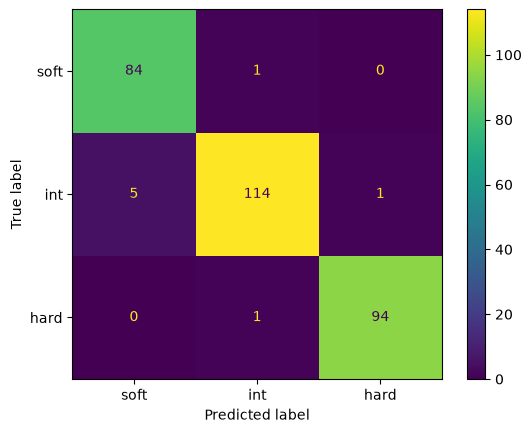

In [3]:
#now turn the above into a non shitty pipeline 
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

#split into training and test data
#stratify keeps the proportions of the different classes identical after splitting
#random_state sets the seed and is useful for when we compare methods with the same
#training/test data
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

#make a pipeline which first scales the data, then fits a logistic regression model to the training data
logistic_pipeline = make_pipeline(StandardScaler(), 
                                  LogisticRegression(max_iter=1000))
logistic_pipeline.fit(X_tr, y_tr)
#now check performance on the test data
print(f"Test accuracy: {logistic_pipeline.score(X_te, y_te)}")

#and the confusion matrix again
#also plot the confusion matrix
ConfusionMatrixDisplay.from_estimator(logistic_pipeline, X_te, y_te, display_labels=["soft", "int", "hard"])
#average recall per class
print(f"Accuracy score: {balanced_accuracy_score(y_te, logistic_pipeline.predict(X_te))}")

#save the classifier 
joblib.dump({"model": logistic_pipeline,
             "sklearn_version": sklearn.__version__,
             "dataset": "data/psd_dataset_only_broadband_1e3.h5", 
             "rms_cut1": end_int, "rms_cut2": start_int,},
             "models/psd_classifier.joblib")

Renormalisation score: 0.73
Renormalisation balanced accuracy: 0.7388028895768834


['models/psd_classifier_renorm.joblib']

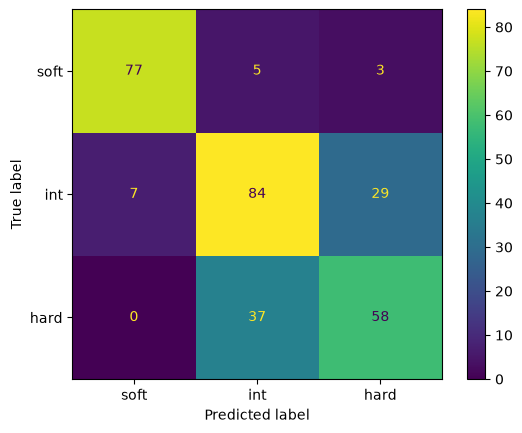

In [5]:
#now let us try to renormalize by the total rms the model started from
#and see if it learns the shape at all
X_norm = X / 10**d["logvar"][:, None]

norm_tr, norm_te = train_test_split(X_norm, test_size=0.3, stratify=y, random_state=0)
norm_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(norm_tr, y_tr)
print(f"Renormalisation score: {norm_pipeline.score(norm_te, y_te)}")

ConfusionMatrixDisplay.from_estimator(norm_pipeline, norm_te, y_te, display_labels=["soft", "int", "hard"])
#average recall per class
print(f"Renormalisation balanced accuracy: {balanced_accuracy_score(y_te, norm_pipeline.predict(norm_te))}")

#so basically the ims, which has a different shape, is reconstructed well
#the soft and hard states are confused because they are both flat-top, and the confusion is made worse
#by the data sometimes having low s:n so the classifier kind of just guesses

#save the classifier 
joblib.dump({"model": norm_pipeline,
             "sklearn_version": sklearn.__version__,
             "dataset": "data/psd_dataset_only_broadband_1e3.h5", 
             "rms_cut1": end_int, "rms_cut2": start_int,},
             "models/psd_classifier_renorm.joblib")

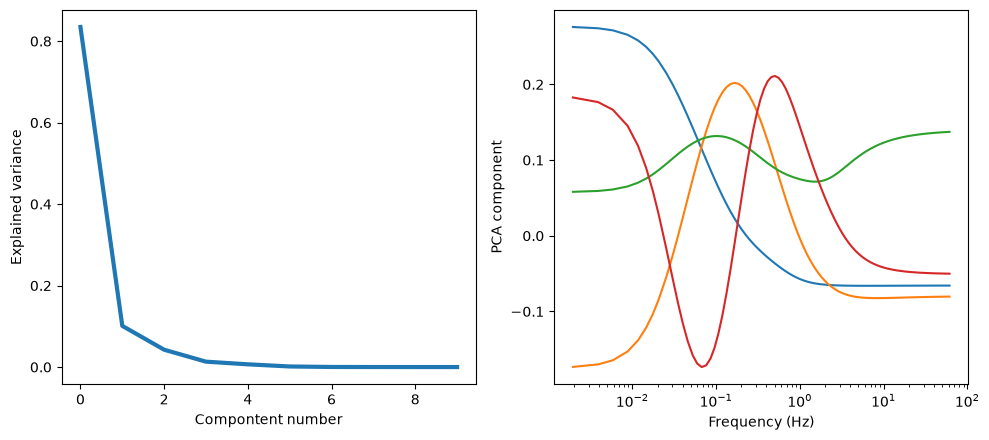

In [6]:
#trying other methods literally does the same because this problem is easy
#now try some unsupervised method starting from PCA
from sklearn.decomposition import PCA

#renormalize by the total variance of each model so that we carry the shape
#take the log to make it easier to handle values
X = np.log10(d["model"]/10**d["logvar"][:, None])
pca = PCA(n_components=10).fit(X)
Z = pca.transform(X)

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10.,4.5))

ax1.plot(pca.explained_variance_ratio_,lw=3)
ax1.set_ylabel("Explained variance")
ax1.set_xlabel("Compontent number")

for index, comp in enumerate(pca.components_[:4]):
    ax2.semilogx(freq, comp,color="C"+str(index))

#ax2.set_yscale("symlog", linthresh=7e-3) 
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("PCA component")

fig.tight_layout()

#save the PCA
joblib.dump({"model": pca,
             "sklearn_version": sklearn.__version__,
             "dataset": "data/psd_dataset_only_broadband_1e3.h5", 
             "rms_cut1": end_int, "rms_cut2": start_int,},
             "models/psd_pca_renorm.joblib")

In [ ]:
#now try the same for the data, but we have to do a bunch of filtering to avoid the noise
mask = freq<16
freq_kept = freq[mask]
data_kept = d["power"][:,mask]
err_kept = d["err"][:,mask]

#renormalize by the median error to reduce the scatter due to the noise
#useful to regularize soft state PSDs
s  = np.median(err_kept / 10**d["logvar"][:, None], axis=0)

#arcsin is like log10 but it's linear near 0 and it can't break for negative bins
Xm = np.arcsinh(d["model"][:, mask] / 10**d["logvar"][:, None] / s)
Xd = np.arcsinh(data_kept / 10**d["logvar"][:, None] / s)

pca_d = PCA(n_components=10).fit(Xd)
pca_m = PCA(n_components=10).fit(Xm)

#pca does a worse job of capturing the variance in the noisy data than in the model
fig, ((ax1,ax2),(ax3,ax4)) = plt.subplots(2,2,figsize=(10.,9.))

ax1.plot(pca_d.explained_variance_ratio_,lw=3)
ax1.set_ylabel("Explained variance")
ax1.set_xlabel("Compontent number")

for index, comp in enumerate(pca_d.components_[:4]):
    ax2.semilogx(freq_kept, comp,color="C"+str(index))

#ax2.set_yscale("symlog", linthresh=7e-3) 
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("PCA component")


ax3.plot(pca_m.explained_variance_ratio_,lw=3)
ax3.set_ylabel("Explained variance")
ax3.set_xlabel("Compontent number")

for index, comp in enumerate(pca_m.components_[:4]):
    ax4.semilogx(freq_kept, comp,color="C"+str(index))

#ax2.set_yscale("symlog", linthresh=7e-3) 
ax4.set_xlabel("Frequency (Hz)")
ax4.set_ylabel("PCA component")

fig.tight_layout()

Zm, Zd = pca_m.transform(Xm), pca_m.transform(Xd)

#but at the same time the components reconstructed from the data or model kind of agree
#but it gets noisy for higher order components when the data also gets noisy
fig, axs = plt.subplots(1,3,figsize=(15.5,4.5))
for index, ax in enumerate(axs):
    sc = ax.scatter(Zm[:, index], Zd[:, index], c=d["logvar"], s=8)
    ax.set_xlabel(f"PC{index+1} from model")
    ax.set_ylabel(f"PC{index+1} from data")

fig.colorbar(sc, ax=axs[-1], label=r"$\log_{10}$ variance")
fig.tight_layout()

#now we compare pc1 vs pc2 in the data and model
#turns out they are both the same, so basically the PCA is learning the same things about the PSDs
#but the data has a lot more uncorrelated noise from one sample to the next (because each changes s:n through count rate
#and exposure) and PCA assumes that each sample has the same scatter, which the data breaks but the model does not
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10.,4.5))

sc = ax1.scatter(Zd[:, 0], Zd[:, 1], c=d["logvar"], s=8)
ax1.set_xlabel(f"Score of PC1 from data samples")
ax1.set_ylabel(f"Score of PC2 from data samples")
ax1.set_xlim([-9,15])
ax1.set_ylim([-13,5.5])

sc = ax2.scatter(Zm[:, 0], Zm[:, 1], c=d["logvar"], s=8)
ax2.set_xlabel(f"Score of PC1 from model samples")
ax2.set_ylabel(f"Score of PC2 from model samples")
ax2.set_xlim([-9,15])
ax2.set_ylim([-13,5.5])

fig.colorbar(sc, ax=ax2, label=r"$\log_{10}$ variance")
fig.tight_layout()

In [ ]:
#if we only keep the data for logvar > -2.5 it gets significantly better
mask_f = freq<16
mask_logvar = d["logvar"] > -2.5
freq_kept = freq[mask_f]
data_kept = d["power"][mask_logvar][:,mask_f]
err_kept = d["err"][mask_logvar][:,mask_f]

s  = np.median(err_kept / 10**d["logvar"][mask_logvar, None], axis=0)

#arcsin is like log10 but it's linear near 0 and it can't break for negative bins
Xm = np.arcsinh(d["model"][mask_logvar][:,mask_f]/ 10**d["logvar"][mask_logvar, None] / s)
Xd = np.arcsinh(data_kept / 10**d["logvar"][mask_logvar, None] / s)

pca_d = PCA(n_components=10).fit(Xd)
pca_m = PCA(n_components=10).fit(Xm)

#pca does a worse job of capturing the variance in the noisy data than in the model
fig, ((ax1,ax2),(ax3,ax4)) = plt.subplots(2,2,figsize=(10.,9.))

ax1.plot(pca_d.explained_variance_ratio_,lw=3)
ax1.set_ylabel("Explained variance")
ax1.set_xlabel("Compontent number")

for index, comp in enumerate(pca_d.components_[:4]):
    ax2.semilogx(freq_kept, comp,color="C"+str(index))

#ax2.set_yscale("symlog", linthresh=7e-3) 
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("PCA component")


ax3.plot(pca_m.explained_variance_ratio_,lw=3)
ax3.set_ylabel("Explained variance")
ax3.set_xlabel("Compontent number")

for index, comp in enumerate(pca_m.components_[:4]):
    ax4.semilogx(freq_kept, comp,color="C"+str(index))

#ax2.set_yscale("symlog", linthresh=7e-3) 
ax4.set_xlabel("Frequency (Hz)")
ax4.set_ylabel("PCA component")

fig.tight_layout()

Zm, Zd = pca_m.transform(Xm), pca_m.transform(Xd)

#but at the same time the components reconstructed from the data or model kind of agree
#but it gets noisy for higher order components when the data also gets noisy
fig, axs = plt.subplots(1,3,figsize=(15.5,4.5))
for index, ax in enumerate(axs):
    sc = ax.scatter(Zm[:, index], Zd[:, index], c=d["logvar"][mask_logvar], s=8)
    ax.set_xlabel(f"PC{index+1} from model")
    ax.set_ylabel(f"PC{index+1} from data")

fig.colorbar(sc, ax=axs[-1], label=r"$\log_{10}$ variance")
fig.tight_layout()

#now we compare the scores pc1 vs pc2 in each sample from the data and model
#turns out they are both the same, so basically the PCA is learning the same things about the PSDs
#but the data has a lot more uncorrelated noise from one sample to the next (because each changes s:n through count rate
#and exposure) and PCA assumes that each sample has the same scatter, which the data breaks but the model does not
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10.,4.5))

sc = ax1.scatter(Zd[:, 0], Zd[:, 1], c=d["logvar"][mask_logvar], s=8)
ax1.set_xlabel(f"Score of PC1 from data samples")
ax1.set_ylabel(f"Score of PC2 from data samples")
ax1.set_xlim([-9,15])
ax1.set_ylim([-13,5.5])

sc = ax2.scatter(Zm[:, 0], Zm[:, 1], c=d["logvar"][mask_logvar], s=8)
ax2.set_xlabel(f"Score of PC1 from model samples")
ax2.set_ylabel(f"Score of PC2 from model samples")
ax2.set_xlim([-9,15])
ax2.set_ylim([-13,5.5])

fig.colorbar(sc, ax=ax2, label=r"$\log_{10}$ variance")
fig.tight_layout()

In [ ]:
from sklearn.neural_network import MLPRegressor

#PCA gets screwed over by the noise in the data because it assumes the noise is the same in every bin and sample, which 
#is true for the model but not the data (since it has different exposures, count rates, and rms values). So we try to 
#build an auto encoder, which is non-linear rather than linear like PCA, to try to capture that structure in the data 
#as well. We use MLPRegressor (note: in scikit-learn regressor means the target is a continuous target of some kind)